<a href="https://colab.research.google.com/github/JWSS-0902/viaiblidade-financeira-short-stay/blob/main/Short_Stay.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Importação de bibliotecas
!pip install numpy-financial
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import numpy_financial as npf
import seaborn as sns
import matplotlib.ticker as mtick
sns.set_theme(style="whitegrid")


In [ ]:
#Premissas do modelo

premissas = {'valor_imovel':375_000,
             'diaria_media':500,
             'dias_ocupados_mes':24,
             'tx_adm': 0.17, 'custos_gerais_mensais':1250,
             'data_assinatura':'2027-01-01', 'prazo_obra_meses':18, 'prazo_plena_meses':26,
             'obra_pedreiro':20, 'inflacao':0.04, 'crescimento_receita': 0.05,
             'pct_reforma': 0.3, 'parcelamento_reforma':12, 'anos_venda':11,
             'valorizacao_imovel':0.05, 'pct_financiado':0.7,
             'prazo_financiamento_meses':420, 'tx_juros_ano':0.12}

In [ ]:
#Função do projeto.

def rodar_modelo(premissas):


    #Fluxos financeiros e de tempo

    #Construção dos parâmetros de referência para identificar os momentos de execução do projeto
    df = pd.DataFrame({"mes":np.arange(0, premissas["anos_venda"]*12+1)})
    df['data'] = pd.date_range(start = premissas['data_assinatura'], periods=len(df), freq = "MS")
    df['ano'] = df['mes'] // 12

    df['fase'] = np.select([df['mes']<premissas['prazo_obra_meses'], df['mes']<premissas['obra_pedreiro'], df['mes']<premissas['prazo_plena_meses'], df['mes'] ==premissas['anos_venda']*12], ['Obra', 'Obra pedreiro','Escalonamento', 'Venda'], default = 'Operação')

    #Fase de escalonamento do projeto, em que nos primeiros meses de operação, o projeto cresce a taxa de 1/(n+1)*i;
    #i é o fator que cresce +1 a cada mês que passa
    df['fator_ocupacao'] = np.select([(df['fase']=='Obra') | (df['fase'] == 'Obra pedreiro') | (df['fase'] == 'Venda'), df['fase'] == 'Escalonamento'], [0, (df['mes'] - premissas['obra_pedreiro']+1)/(premissas['prazo_plena_meses']-premissas['obra_pedreiro']+1)], default=1)

    #Linhas de receita, de despesas e reforma imóvel
    receita_plena = premissas['diaria_media'] * premissas['dias_ocupados_mes']
    df['receita_bruta'] = df['fator_ocupacao'] * receita_plena


    df['receita_bruta_reajustada'] = df['receita_bruta'] * ((1+premissas['crescimento_receita'])**(df['ano']))

    df['custos_gerais'] = np.where((df['mes']>=premissas['prazo_obra_meses']) & (df['fase'] != "Venda"), premissas['custos_gerais_mensais']*((1+premissas['inflacao'])**(df['ano'])), 0)

    df['tx_de_adm'] = df['receita_bruta_reajustada']*premissas['tx_adm']

    df['custo_reforma'] = np.select([(df['mes']>=premissas['prazo_obra_meses']) & (df['mes']<premissas['prazo_obra_meses']+premissas['parcelamento_reforma'])],
                                    [(premissas['valor_imovel']*(premissas['pct_reforma']))/
                                    (premissas['parcelamento_reforma'])], default=0)

    df['fluxo_operacional'] = df['receita_bruta_reajustada']-df['custos_gerais']-df['tx_de_adm']

    #Venda do imóvel

    df['venda_imovel'] = np.where(df['fase'] == 'Venda',
                                premissas['valor_imovel']*((1+premissas['valorizacao_imovel'])
                                **premissas['anos_venda']), 0)

    #Financiamento
    df['entrada'] = np.where(df['mes']==0, premissas['valor_imovel']*(1-premissas['pct_financiado']),0)


    df['amortizacao'] = np.select([(df['mes']>=1) & (df['mes']<=premissas['prazo_financiamento_meses']) & (df['mes']<premissas['anos_venda']*12)],
    [(premissas['valor_imovel']*premissas['pct_financiado'])/(premissas['prazo_financiamento_meses'])],default=0)

    df['saldo_devedor'] = np.where(df['mes']<premissas['anos_venda']*12,premissas['valor_imovel'] - df['entrada'].cumsum() - df['amortizacao'].cumsum(),0)

    df['juro'] = np.where(df['mes']<premissas['anos_venda']*12, df['saldo_devedor'].shift(1) * (((1+premissas['tx_juros_ano'])**(1/12))-1),0)
    df['juro'] = df['juro'].fillna(0)
    df['parcela'] = np.where(df['mes']<premissas['anos_venda']*12, df['amortizacao'] + df['juro'],0)

    df['quitacao'] = np.where(df['fase'] == 'Venda', df['saldo_devedor'].nsmallest(2).iloc[-1],0)

    df['fluxo_acionista'] = df['fluxo_operacional'] + df['venda_imovel'] - df['custo_reforma'] - df['entrada'] - df['parcela'] - df['quitacao']
    df['fluxo_projeto'] = df['fluxo_operacional'] + df['venda_imovel'] - df['custo_reforma'] - np.where(df['mes']==0,premissas['valor_imovel'],0)

    return df

#Cálculo da TIR
def calcular_tirs(df):
    tir_acionista = ((1+npf.irr(df['fluxo_acionista']))**12)-1
    tir_projeto = ((1+npf.irr(df['fluxo_projeto']))**12)-1
    return tir_acionista, tir_projeto



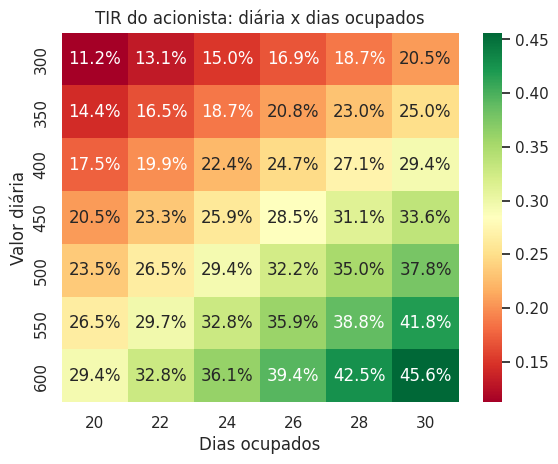

In [ ]:
#Sensibilidade diária x ocupação

#Lista de diárias/dia e dias ocupados no mês (varia entre 0 e 30 dias ocupados)
diarias = [300, 350, 400, 450, 500, 550, 600]
dias = [20, 22, 24, 26, 28, 30]

resultados = []

#Contrução de cada cenário possível em loop
for diaria in diarias:
    for dia in dias:
        cenario = dict(premissas, diaria_media=diaria, dias_ocupados_mes=dia)
        df_cenario = rodar_modelo(cenario)
        tir_acionista, tir_projeto = calcular_tirs(df_cenario)
        resultados.append({'diarias': diaria, 'dias': dia, 'tir_acionista': tir_acionista})

tabela = pd.DataFrame(resultados)

tabela_sns = tabela.pivot(index='diarias', columns='dias', values='tir_acionista')

#Mapa de calor valor diárias X dias ocupados
plt.title('TIR do acionista: diária x dias ocupados')
sns.heatmap(tabela_sns, annot=True, fmt=".1%", cmap='RdYlGn')
plt.xlabel('Dias ocupados')
plt.ylabel('Valor diária')
plt.show()

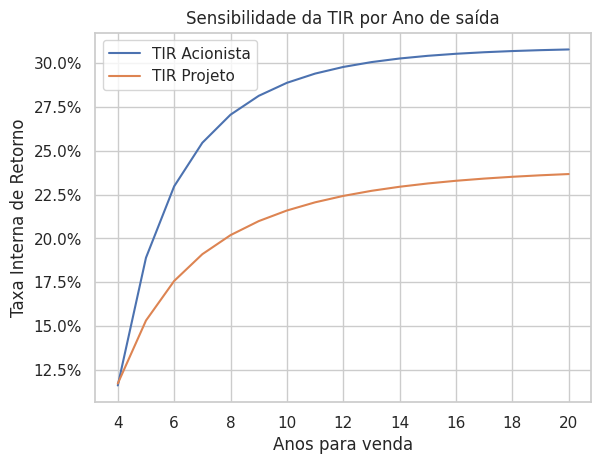

In [ ]:
#Sensibilidade de quantos anos você fica com o imóvel e qual o retorno.

#Período analisad0
anos_saida = np.arange(4,21,1)
resultados_saida = []

#Laços com os anos de saída e as respectivas TIR
for ano in anos_saida:
    cenario_saida = dict(premissas, anos_venda = ano)
    df_cenario_saida = rodar_modelo(cenario_saida)
    tir_acionista, tir_projeto = calcular_tirs(df_cenario_saida)
    resultados_saida.append({'ano': ano, 'tir_acionista': tir_acionista,'tir_projeto': tir_projeto})

tabela_saida = pd.DataFrame(resultados_saida)

#Gráfico de saída, cada tir o resultado por ano

fig, ax = plt.subplots()

sns.lineplot(data=tabela_saida, x = 'ano', y='tir_acionista', label = 'TIR Acionista', ax=ax)
sns.lineplot(data=tabela_saida, x = 'ano', y = 'tir_projeto', label = 'TIR Projeto', ax=ax)
ax.set_ylabel('Taxa Interna de Retorno')
ax.set_xlabel('Anos para venda')
ax.set_title ('Sensibilidade da TIR por Ano de saída')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=1))
plt.show()

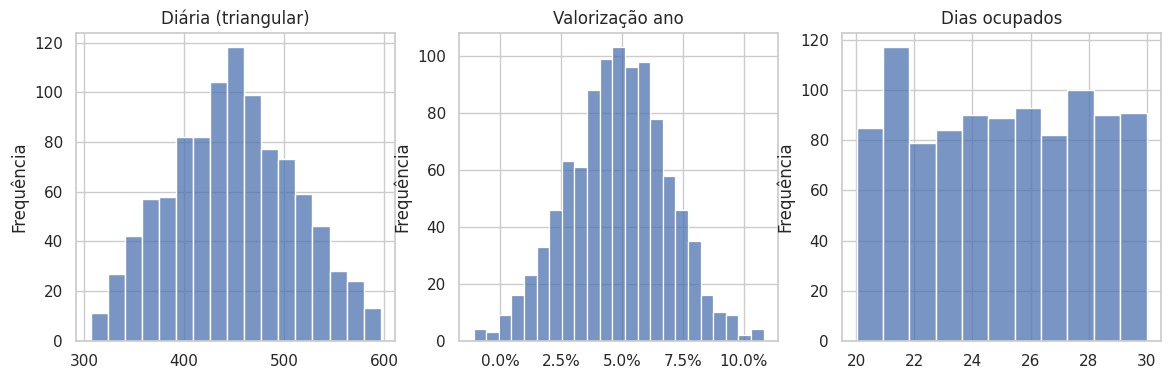

In [ ]:
#Teste de Monte Carlo

#Simulados 1k de cenários: dias ocupados, valorização e diária média
n = 1000
rng = np.random.default_rng(42)

dias_ocupados_mes = rng.uniform(20, 30, size = n)
valorizacoes_testes = rng.normal(0.05, 0.02, size = n)
diarias_medias = rng.triangular(300, 450, 600, size = n)

#Histograma
fig, axes = plt.subplots(1, 3, figsize=(14,4))

sns.histplot(diarias_medias, ax=axes[0])
axes[0].set_title('Diária (triangular)')
axes[0].set_ylabel('Frequência')

sns.histplot(valorizacoes_testes, ax=axes[1])
axes[1].set_title('Valorização ano')
axes[1].set_ylabel('Frequência')
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=1))


sns.histplot(dias_ocupados_mes, ax=axes[2])
axes[2].set_title('Dias ocupados')
axes[2].set_ylabel('Frequência')

plt.show()

In [ ]:
#Expectativa TIR a partir dos números aleatórios com 1k combinação de resultados

resultados_mc = []

for dia_ocupado, valorizacao_teste, diaria_media in zip(dias_ocupados_mes,
                                                        valorizacoes_testes, diarias_medias):
    cenario_mc = dict(premissas, diaria_media = diaria_media, dias_ocupados_mes = dia_ocupado,
                      valorizacao_imovel = valorizacao_teste)
    df_cenario_mc = rodar_modelo(cenario_mc)
    tir_acionista, tir_projeto = calcular_tirs(df_cenario_mc)
    resultados_mc.append({'dias_ocupados': dia_ocupado, 'valorizacao': valorizacao_teste,
                                  'diaria_media':diaria_media,
                                  'tir_acionista': tir_acionista, 'tir_projeto': tir_projeto})

tabela_mc = pd.DataFrame(resultados_mc)
tabela_mc

,dias_ocupados,valorizacao,diaria_media,tir_acionista,tir_projeto
0,27.739560,0.035156,379.312304,0.243376,0.190383
1,24.388784,0.068487,440.884649,0.267636,0.207265
2,28.585979,0.050692,436.550063,0.308020,0.228583
3,26.973680,0.044344,453.318166,0.298303,0.222439
4,20.941773,0.047876,412.176802,0.192658,0.162236
...,...,...,...,...,...
995,24.379896,0.044582,370.595781,0.202860,0.167908
996,26.390136,0.045277,359.814299,0.217456,0.176341
997,20.023088,0.035312,494.111545,0.223974,0.179352
998,29.933685,0.059702,414.813396,0.309927,0.230588


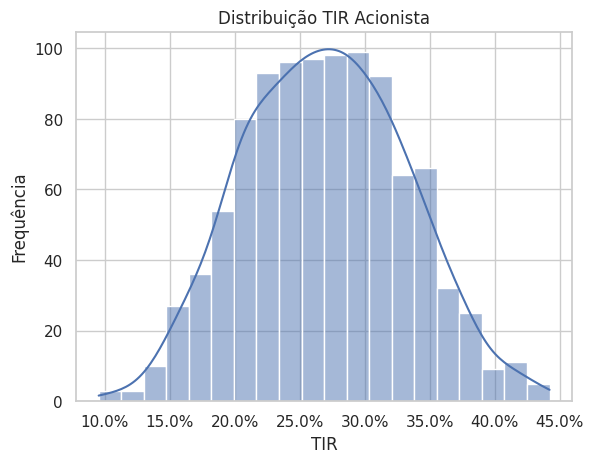

In [ ]:
#Histograma Monte Carlo das TIRs a partir da combinação de 1k cenários
 #(valores médio diárias, nível de ocupação/mês e expectativa valorização )

fig, ax = plt.subplots()

sns.histplot(tabela_mc['tir_acionista'], ax=ax, kde=True)
ax.set_title('Distribuição TIR Acionista')
ax.set_ylabel('Frequência')
ax.set_xlabel('TIR')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=1))

plt.show()


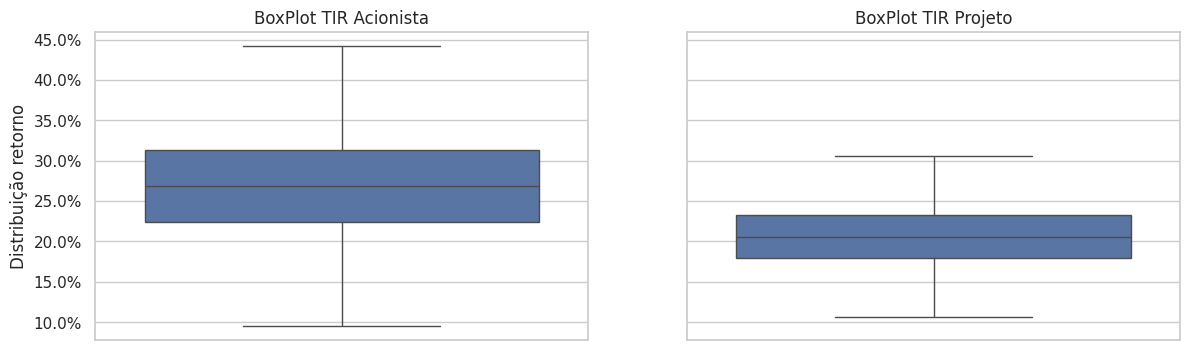

In [23]:
#Boxplot resultados TIR por cada trio de variáveis; Monte Carlo

fig, axes = plt.subplots(1, 2, figsize=(14,4), sharey=True)

sns.boxplot(tabela_mc['tir_acionista'], ax=axes[0])
axes[0].set_title('BoxPlot TIR Acionista')
axes[0].set_ylabel('Distribuição retorno')
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=1))

sns.boxplot(tabela_mc['tir_projeto'], ax=axes[1])
axes[1].set_title('BoxPlot TIR Projeto')
axes[1].set_ylabel('Distribuição retorno')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=1))

plt.show()

In [ ]:
#Resumo estatístico com retornos abaixo do custo de k

cenario_abaixo_12 = tabela_mc[tabela_mc['tir_acionista'] <= 0.12]
cenario_abaixo_12



,dias_ocupados,valorizacao,diaria_media,tir_acionista,tir_projeto
338,20.844932,0.000386,350.328884,0.111254,0.115079
414,20.289995,-0.007341,355.569223,0.101442,0.109897
547,20.800493,0.016353,337.346559,0.114021,0.116497
554,20.446491,-0.004994,343.085803,0.095307,0.106581


In [ ]:
(tabela_mc[tabela_mc['tir_acionista'] <= 0.12]).mean()

,0
dias_ocupados,20.595478
valorizacao,0.001101
diaria_media,346.582618
tir_acionista,0.105506
tir_projeto,0.112014


In [ ]:
#Correlação entre as variáveis; a valorização traz pouco impacto na tir, enquanto diária e dias ocupados valoriza mais.

tabela_mc[['dias_ocupados', 'valorizacao', 'diaria_media', 'tir_acionista']].corr()

,dias_ocupados,valorizacao,diaria_media,tir_acionista
dias_ocupados,1.000000,0.058203,0.055063,0.665593
valorizacao,0.058203,1.000000,0.039308,0.230682
diaria_media,0.055063,0.039308,1.000000,0.758910
tir_acionista,0.665593,0.230682,0.758910,1.000000


In [ ]:
#Descriçaõ do resultado do teste de Monte Carlo

tabela_mc['tir_acionista'].rename("TIR Acionista").describe().to_frame().style.format("{:.1%}")


,TIR Acionista
count,100000.0%
mean,27.0%
std,6.2%
min,9.5%
25%,22.4%
50%,26.9%
75%,31.4%
max,44.2%


In [24]:
#Quartis

tabela_mc['tir_acionista'].rename('Tir Acionista').quantile([0.05, 0.5, 0.95]).to_frame().style.format('{:.1%}')

,Tir Acionista
0.050000,17.0%
0.500000,26.9%
0.950000,37.3%
